# Dataset audit: CottonWeedDet12
Counts, box sizes and split balance, using the JSON-based labels
(`data/processed/labels`) and the frozen manifest `configs/split_v1.json`.

In [7]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
audit = pd.read_csv(ROOT / "reports" / "image_audit.csv")
manifest = json.loads((ROOT / "configs" / "split_v1.json").read_text())

CLASS_NAMES = [
    "Waterhemp",
    "Morning glory",
    "Purslane",
    "Spotted spurge",
    "Carpetweed",
    "Ragweed",
    "Eclipta",
    "Prickly sida",
    "Palmer amaranth",
    "Sicklepod",
    "Goosegrass",
    "Cutleaf groundcherry",
]

rows = []
for path in sorted((ROOT / "data" / "processed" / "labels").glob("*.txt")):
    for line in path.read_text().splitlines():
        if line.strip():
            c, x, y, w, h = line.split()
            rows.append((path.stem, int(c), float(w), float(h)))
boxes = pd.DataFrame(rows, columns=["stem", "cls", "w", "h"])
boxes = boxes.merge(audit[["stem", "width", "height"]], on="stem")
boxes["area_frac"] = boxes.w * boxes.h
boxes["species"] = boxes.cls.map(dict(enumerate(CLASS_NAMES)))
print(len(boxes), "boxes in", boxes.stem.nunique(), "images")

9370 boxes in 5648 images


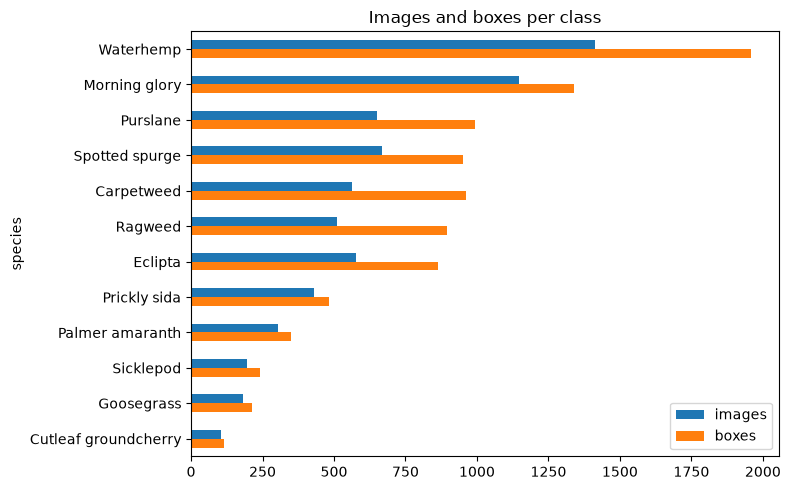

,images,boxes
species,,
Waterhemp,1413,1959
Morning glory,1146,1341
Purslane,652,992
Spotted spurge,667,952
Carpetweed,564,962
Ragweed,512,896
Eclipta,576,865
Prickly sida,431,484
Palmer amaranth,305,348


In [8]:
per_class = pd.DataFrame(
    {
        "images": boxes.groupby("species").stem.nunique(),
        "boxes": boxes.groupby("species").size(),
    }
).reindex(CLASS_NAMES)
ax = per_class.plot.barh(figsize=(8, 5))
ax.invert_yaxis()
ax.set_title("Images and boxes per class")
plt.tight_layout()
plt.show()
per_class

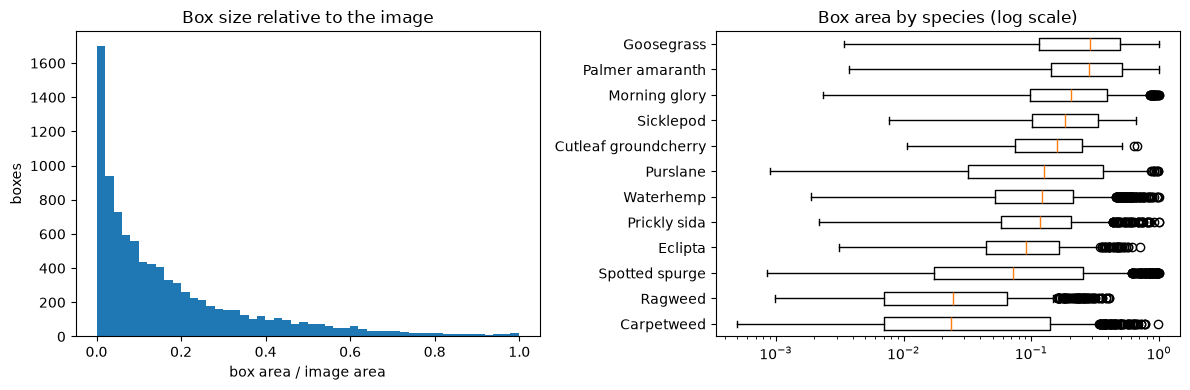

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(boxes.area_frac, bins=50)
axes[0].set_xlabel("box area / image area")
axes[0].set_ylabel("boxes")
axes[0].set_title("Box size relative to the image")
order = boxes.groupby("species").area_frac.median().sort_values().index
axes[1].boxplot([boxes[boxes.species == s].area_frac for s in order], orientation="horizontal")
axes[1].set_yticklabels(order)
axes[1].set_xscale("log")
axes[1].set_title("Box area by species (log scale)")
plt.tight_layout()
plt.show()

In [10]:
scale = 640 / boxes[["width", "height"]].max(axis=1)
short_side = boxes[["w", "h"]].mul(boxes[["width", "height"]].values).min(axis=1) * scale
print(f"boxes with a short side under 32 px at 640: {(short_side < 32).mean():.1%}")
short_side.describe()

boxes with a short side under 32 px at 640: 4.5%


count    9370.000000
mean      182.502914
std       116.153363
min        12.167465
25%        89.301240
50%       163.133867
75%       251.746040
max       619.652480
dtype: float64

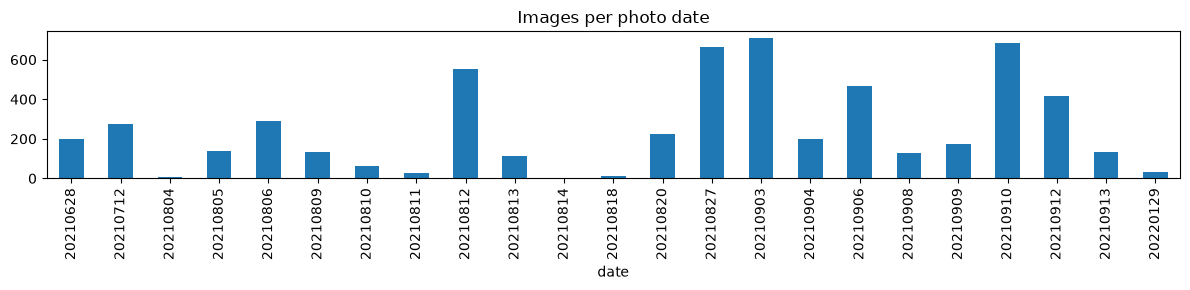

In [11]:
per_date = audit.groupby("date").size()
ax = per_date.plot.bar(figsize=(12, 3))
ax.set_title("Images per photo date")
plt.tight_layout()
plt.show()

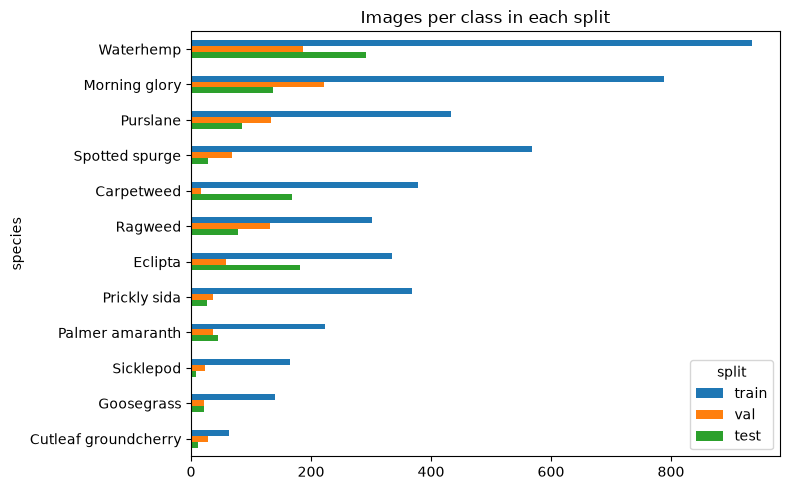

split,train,val,test
species,,,
Waterhemp,935,187,291
Morning glory,788,221,137
Purslane,433,134,85
Spotted spurge,569,69,29
Carpetweed,379,16,169
Ragweed,302,132,78
Eclipta,335,59,182
Prickly sida,368,36,27
Palmer amaranth,224,36,45


In [12]:
split_of = {s: sp for sp, stems in manifest["images"].items() for s in stems}
boxes["split"] = boxes.stem.map(split_of)
counts = (
    boxes.groupby(["species", "split"])
    .stem.nunique()
    .unstack()
    .reindex(CLASS_NAMES)[["train", "val", "test"]]
)
ax = counts.plot.barh(figsize=(8, 5))
ax.invert_yaxis()
ax.set_title("Images per class in each split")
plt.tight_layout()
plt.show()
counts

## Findings
- 5,648 images, 9,370 boxes, 12 classes. Every image has at least one weed.
- Strong imbalance: 104 (Cutleaf groundcherry) to 1,413 (Waterhemp) images per class.
- The shipped YOLO labels contained 18 stray boxes in 14 images, all from the
  2021-09-03 session. Labels are rebuilt from the VGG JSON instead.
- Boxes are large relative to the images. After resizing to 640 px the median
  short side is about 163 px and 4.5% of boxes are under 32 px, so 640 px input
  is a reasonable default.
- Photo dates differ a lot in size, so a date-grouped split cannot be exactly
  balanced. Carpetweed has only 16 images in validation and Sicklepod only 8 in
  test, so per-class numbers for those are noisy.